In [2]:
!git clone https://github.com/alexeygrigorev/clothing-dataset-small.git

Cloning into 'clothing-dataset-small'...
remote: Enumerating objects: 3839, done.
remote: Counting objects: 100% (400/400), done.
remote: Compressing objects: 100% (400/400), done.
remote: Total 3839 (delta 9), reused 385 (delta 0), pack-reused 3439 (from 1)
Receiving objects: 100% (3839/3839), 100.58 MiB | 18.91 MiB/s, done.
Resolving deltas: 100% (10/10), done.


In [3]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
%matplotlib inline

import tensorflow as tf
from tensorflow import keras

In [4]:
from tensorflow.keras.preprocessing.image import load_img

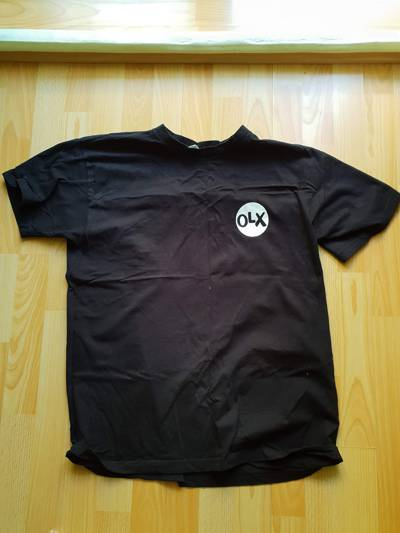

In [5]:
path = './clothing-dataset-small/train/t-shirt'
name = '5f0a3fa0-6a3d-4b68-b213-72766a643de7.jpg'
fullname = f'{path}/{name}'
load_img(fullname)

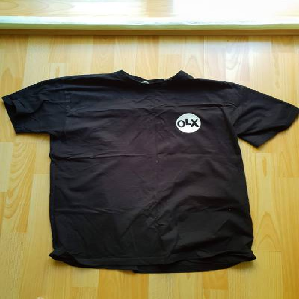

In [6]:
img = load_img(fullname, target_size=(299, 299))
img

In [7]:
x = np.array(img)
x.shape

(299, 299, 3)

array([[[179, 171,  99],
        [179, 171,  99],
        [181, 173, 101],
        ...,
        [251, 253, 248],
        [251, 253, 248],
        [251, 254, 247]],

       [[188, 179, 112],
        [187, 178, 111],
        [186, 177, 108],
        ...,
        [251, 252, 247],
        [251, 252, 247],
        [251, 252, 246]],

       [[199, 189, 127],
        [200, 190, 128],
        [200, 191, 126],
        ...,
        [250, 251, 245],
        [250, 251, 245],
        [250, 251, 245]],

       ...,

       [[165, 151,  76],
        [173, 159,  84],
        [171, 157,  82],
        ...,
        [183, 135,  25],
        [181, 133,  22],
        [183, 135,  24]],

       [[165, 151,  76],
        [173, 159,  84],
        [171, 157,  82],
        ...,
        [182, 134,  23],
        [180, 132,  21],
        [182, 134,  23]],

       [[165, 151,  76],
        [173, 159,  84],
        [171, 157,  82],
        ...,
        [181, 133,  22],
        [179, 131,  20],
        [182, 134,  23]]], dtype=uint8)
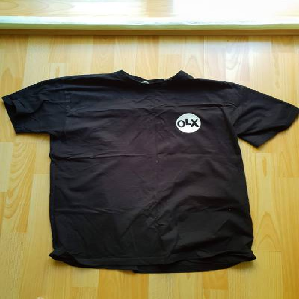

In [8]:
x

In [9]:
from tensorflow.keras.applications.xception import Xception
from tensorflow.keras.applications.xception import preprocess_input
from tensorflow.keras.applications.xception import decode_predictions

In [10]:
model = Xception(weights='imagenet', input_shape=(299, 299, 3))

91884032/91884032 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step


In [11]:
X = np.array([x])
X.shape

(1, 299, 299, 3)

In [12]:
X = preprocess_input(X)

In [13]:
pred = model.predict(X)
pred.shape

1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step


(1, 1000)

In [14]:
decode_predictions(pred)

35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step


[[('n03595614', 'jersey', np.float32(0.6819637)),
  ('n02916936', 'bulletproof_vest', np.float32(0.038139876)),
  ('n04370456', 'sweatshirt', np.float32(0.03432469)),
  ('n03710637', 'maillot', np.float32(0.011354209)),
  ('n04525038', 'velvet', np.float32(0.0018453572))]]

In [15]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [16]:
train_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_ds = train_gen.flow_from_directory(
    './clothing-dataset-small/train',
    target_size=(150, 150),
    batch_size=32
)

Found 3068 images belonging to 10 classes.


In [17]:
X, y = next(train_ds)

In [18]:
X.shape

(32, 150, 150, 3)

In [19]:
val_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

val_ds = val_gen.flow_from_directory(
    './clothing-dataset-small/validation',
    target_size=(150, 150),
    batch_size=32,
    shuffle=False
)

Found 341 images belonging to 10 classes.


In [26]:
def make_model(learning_rate=0.01):
    base_model = Xception(
        weights='imagenet',
        include_top=False,
        input_shape=(150, 150, 3)
    )

    base_model.trainable = False

    #########################################

    inputs = keras.Input(shape=(150, 150, 3))
    base = base_model(inputs, training=False)
    vectors = keras.layers.GlobalAveragePooling2D()(base)
    outputs = keras.layers.Dense(10)(vectors)
    model = keras.Model(inputs, outputs)

    #########################################

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    loss = keras.losses.CategoricalCrossentropy(from_logits=True)

    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=['accuracy']
    )

    return model

In [27]:
scores = {}

for lr in [0.0001, 0.001, 0.01, 0.1]:
    print(lr)

    model = make_model(learning_rate=lr)
    history = model.fit(train_ds, epochs=10, validation_data=val_ds)
    scores[lr] = history.history

    print()
    print()

0.0001
Epoch 1/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 28s 213ms/step - accuracy: 0.2911 - loss: 2.0414 - val_accuracy: 0.4897 - val_loss: 1.6498
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 11s 114ms/step - accuracy: 0.5492 - loss: 1.4431 - val_accuracy: 0.6041 - val_loss: 1.2745
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - accuracy: 0.6424 - loss: 1.1736 - val_accuracy: 0.6833 - val_loss: 1.0748
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 102ms/step - accuracy: 0.6907 - loss: 1.0209 - val_accuracy: 0.7126 - val_loss: 0.9624
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 104ms/step - accuracy: 0.7223 - loss: 0.9207 - val_accuracy: 0.7185 - val_loss: 0.8837
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 11s 116ms/step - accuracy: 0.7422 - loss: 0.8496 - val_accuracy: 0.7419 - val_loss: 0.8300
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 11s 110ms/step - accuracy: 0.7542 - loss: 0.7942 - val_accuracy: 0.7507 - val_loss: 0.7885
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 102ms/step - accuracy: 0.7653 - loss: 0.7498 - v

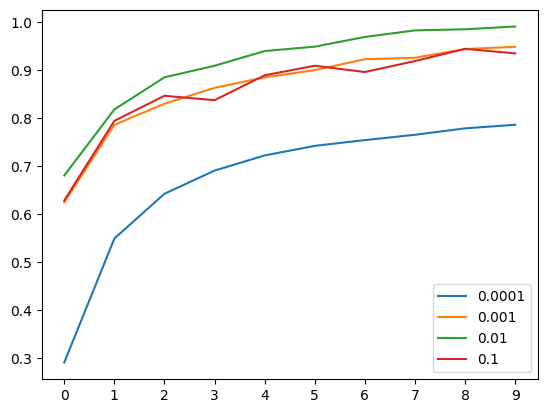

In [28]:
for lr, hist in scores.items():
    plt.plot(hist['accuracy'], label=lr)

plt.xticks(np.arange(10))
plt.legend()

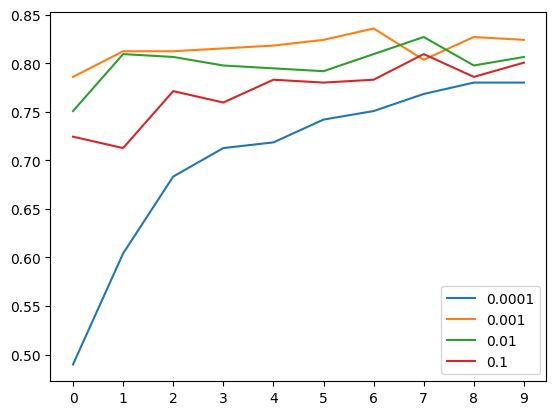

In [29]:
for lr, hist in scores.items():
    plt.plot(hist['val_accuracy'], label=lr)

plt.xticks(np.arange(10))
plt.legend()

In [30]:
del scores[0.1]
del scores[0.0001]

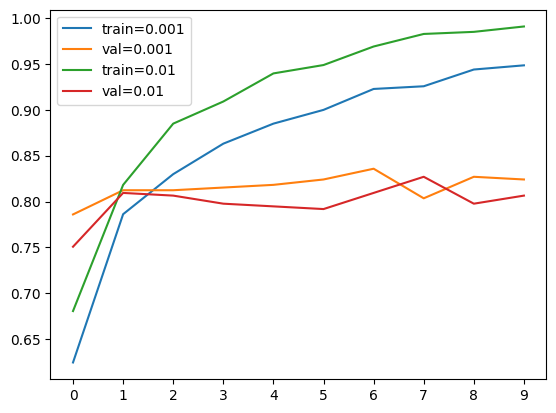

In [32]:
for lr, hist in scores.items():
    plt.plot(hist['accuracy'], label=('train=%s' % lr))
    plt.plot(hist['val_accuracy'], label=('val=%s' %lr))

plt.xticks(np.arange(10))
plt.legend()

In [33]:
learning_rate = 0.001

In [37]:
model.save_weights('model_v1.weights.h5')

In [38]:
checkpoint = keras.callbacks.ModelCheckpoint(
    'xception_v1_{epoch:02d}_{val_accuracy:.3f}.h5',
    save_best_only=True,
    monitor='val_accuracy',
    mode='max'
)

In [39]:
learning_rate = 0.001

model = make_model(learning_rate=learning_rate)

history = model.fit(
    train_ds,
    epochs=10,
    validation_data=val_ds,
    callbacks=[checkpoint]
)

Epoch 1/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.4996 - loss: 1.5090

96/96 ━━━━━━━━━━━━━━━━━━━━ 26s 194ms/step - accuracy: 0.6180 - loss: 1.1271 - val_accuracy: 0.7683 - val_loss: 0.7433
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.7959 - loss: 0.6170

96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 99ms/step - accuracy: 0.7846 - loss: 0.6378 - val_accuracy: 0.8152 - val_loss: 0.6283
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.8224 - loss: 0.5189

96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 104ms/step - accuracy: 0.8217 - loss: 0.5186 - val_accuracy: 0.8211 - val_loss: 0.5832
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 106ms/step - accuracy: 0.8602 - loss: 0.4369 - val_accuracy: 0.8152 - val_loss: 0.5664
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 97ms/step - accuracy: 0.8931 - loss: 0.3747 - val_accuracy: 0.8035 - val_loss: 0.5654
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9063 - loss: 0.3195

96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 96ms/step - accuracy: 0.9032 - loss: 0.3312 - val_accuracy: 0.8240 - val_loss: 0.5348
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.9206 - loss: 0.2878

96/96 ━━━━━━━━━━━━━━━━━━━━ 11s 110ms/step - accuracy: 0.9162 - loss: 0.2943 - val_accuracy: 0.8387 - val_loss: 0.5320
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 105ms/step - accuracy: 0.9338 - loss: 0.2621 - val_accuracy: 0.8299 - val_loss: 0.5320
Epoch 9/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 92ms/step - accuracy: 0.9426 - loss: 0.2355 - val_accuracy: 0.8270 - val_loss: 0.5290
Epoch 10/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 100ms/step - accuracy: 0.9514 - loss: 0.2114 - val_accuracy: 0.8240 - val_loss: 0.5480


In [40]:
def make_model(learning_rate=0.01, size_inner=100):
    base_model = Xception(
        weights='imagenet',
        include_top=False,
        input_shape=(150, 150, 3)
    )

    base_model.trainable = False

    #########################################

    inputs = keras.Input(shape=(150, 150, 3))
    base = base_model(inputs, training=False)
    vectors = keras.layers.GlobalAveragePooling2D()(base)

    inner = keras.layers.Dense(size_inner, activation='relu')(vectors)

    outputs = keras.layers.Dense(10)(inner)

    model = keras.Model(inputs, outputs)

    #########################################

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    loss = keras.losses.CategoricalCrossentropy(from_logits=True)

    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=['accuracy']
    )

    return model

In [41]:
learning_rate = 0.001

scores = {}

for size in [10, 100, 1000]:
    print(size)

    model = make_model(learning_rate=learning_rate, size_inner=size)
    history = model.fit(train_ds, epochs=10, validation_data=val_ds)
    scores[size] = history.history

    print()
    print()

10
Epoch 1/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 25s 191ms/step - accuracy: 0.5332 - loss: 1.5054 - val_accuracy: 0.6657 - val_loss: 1.0499
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 93ms/step - accuracy: 0.7154 - loss: 0.8701 - val_accuracy: 0.7713 - val_loss: 0.7742
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 99ms/step - accuracy: 0.7800 - loss: 0.6493 - val_accuracy: 0.8182 - val_loss: 0.6496
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - accuracy: 0.8224 - loss: 0.5299 - val_accuracy: 0.7947 - val_loss: 0.6414
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 99ms/step - accuracy: 0.8553 - loss: 0.4461 - val_accuracy: 0.8270 - val_loss: 0.5806
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 93ms/step - accuracy: 0.8843 - loss: 0.3832 - val_accuracy: 0.8123 - val_loss: 0.5516
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 101ms/step - accuracy: 0.9032 - loss: 0.3282 - val_accuracy: 0.8152 - val_loss: 0.5523
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 103ms/step - accuracy: 0.9192 - loss: 0.2887 - val_accurac

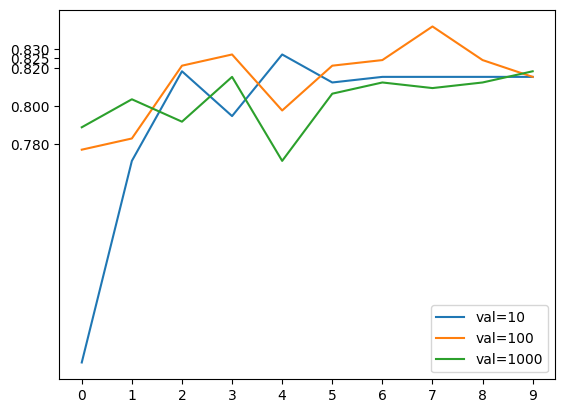

In [42]:
for size, hist in scores.items():
    plt.plot(hist['val_accuracy'], label=('val=%s' % size))

plt.xticks(np.arange(10))
plt.yticks([0.78, 0.80, 0.82, 0.825, 0.83])
plt.legend()

In [43]:
def make_model(learning_rate=0.01, size_inner=100, droprate=0.5):
    base_model = Xception(
        weights='imagenet',
        include_top=False,
        input_shape=(150, 150, 3)
    )

    base_model.trainable = False

    #########################################

    inputs = keras.Input(shape=(150, 150, 3))
    base = base_model(inputs, training=False)
    vectors = keras.layers.GlobalAveragePooling2D()(base)

    inner = keras.layers.Dense(size_inner, activation='relu')(vectors)
    drop = keras.layers.Dropout(droprate)(inner)

    outputs = keras.layers.Dense(10)(drop)

    model = keras.Model(inputs, outputs)

    #########################################

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    loss = keras.losses.CategoricalCrossentropy(from_logits=True)

    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=['accuracy']
    )

    return model

In [44]:
learning_rate = 0.001
size = 100

scores = {}

for droprate in [0.0, 0.2, 0.5, 0.8]:
    print(droprate)

    model = make_model(
        learning_rate=learning_rate,
        size_inner=size,
        droprate=droprate
    )

    history = model.fit(train_ds, epochs=30, validation_data=val_ds)
    scores[droprate] = history.history

    print()
    print()

0.0
Epoch 1/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 25s 185ms/step - accuracy: 0.6773 - loss: 0.9590 - val_accuracy: 0.7830 - val_loss: 0.6498
Epoch 2/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 30s 99ms/step - accuracy: 0.8380 - loss: 0.4891 - val_accuracy: 0.8035 - val_loss: 0.5765
Epoch 3/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 104ms/step - accuracy: 0.8892 - loss: 0.3335 - val_accuracy: 0.7947 - val_loss: 0.5497
Epoch 4/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 101ms/step - accuracy: 0.9201 - loss: 0.2474 - val_accuracy: 0.8123 - val_loss: 0.5323
Epoch 5/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 95ms/step - accuracy: 0.9570 - loss: 0.1656 - val_accuracy: 0.8123 - val_loss: 0.5361
Epoch 6/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 95ms/step - accuracy: 0.9762 - loss: 0.1140 - val_accuracy: 0.8065 - val_loss: 0.5585
Epoch 7/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 104ms/step - accuracy: 0.9873 - loss: 0.0808 - val_accuracy: 0.8065 - val_loss: 0.5821
Epoch 8/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 99ms/step - accuracy: 0.9945 - loss: 0.0560 - val_accura

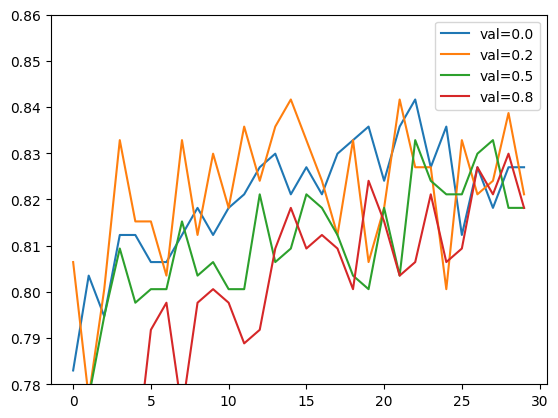

In [45]:
for droprate, hist in scores.items():
    plt.plot(hist['val_accuracy'], label=('val=%s' % droprate))

plt.ylim(0.78, 0.86)
plt.legend()

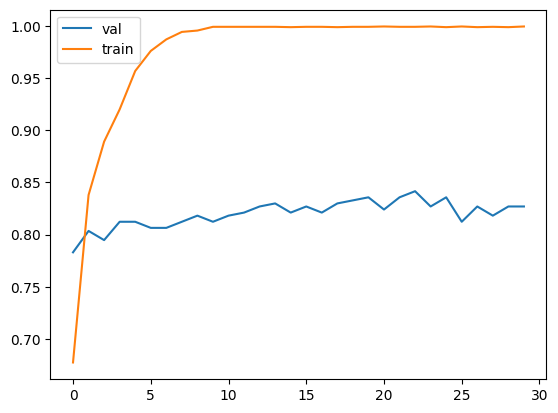

In [46]:
hist = scores[0.0]
plt.plot(hist['val_accuracy'], label='val')
plt.plot(hist['accuracy'], label='train')

plt.legend()